# Chance level C vs IP: epochs mínims i mapa temps×elèctrode

**Tres preguntes:**
1. Quants epochs calen (aprox.) per superar el chance level en C vs IP?
2. Per a cada elèctrode, a partir de quin instant se supera chance level?
3. A nivell de grup, on i quan podem afirmar que l'accuracy supera chance?

**Metodologia:**
- Surrogate per permutació d'etiquetes, **per subjecte × elèctrode × finestra temporal**.
- ΔAcc = Acc_real(t) − Acc_chance(t)
- Contrast de grup: paired t-test one-tailed vectoritzat + FDR per cel·la (canal, t).
- Paral·lelisme: `joblib.Parallel` (N_JOBS) sobre subjectes.
- Els tensors intermedis es desen a disc per evitar recalcular si el kernel cau.


In [1]:
import warnings
from pathlib import Path
from scipy.signal import hilbert
import matplotlib.pyplot as plt
import seaborn as sns
import mne
import numpy as np
import pandas as pd
from joblib import Parallel, delayed, cpu_count
from scipy.stats import ttest_rel
from sklearn.linear_model import LogisticRegressionCV
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import sys

# Add src directory to path so we can import br_analysis
src_path = Path(r"c:\Users\nils\Documents\Universitat\TFG\src")
if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))

from br_analysis import detect_project_paths, get_task_config, get_epochs_grid, COMMON_BAND_RANGES

try:
    from google.colab import drive

    IN_COLAB = True
except ImportError:
    drive = None
    IN_COLAB = False

warnings.filterwarnings("ignore", category=RuntimeWarning)
mne.set_log_level("WARNING")

if IN_COLAB:
    drive.mount("/content/drive")

paths = detect_project_paths("c_vs_i", in_colab=IN_COLAB)
PROJECT_DIR = paths.project_dir
BASE_DIR = paths.project_dir
DATA_DIR = paths.data_dir
ANALYSIS_ROOT = paths.analysis_root
ANALYSIS_DIR = paths.analysis_dir
CACHE_DIR = paths.cache_dir
TABLES_DIR = paths.tables_dir
FIGURES_DIR = paths.figures_dir
DATA_FILES = paths.data_files

# Centralized experiment imports
from br_analysis.experiments import ChanceLevelExperiment, TimeWindowGrid, ExperimentSettings
from br_analysis.models import LogRegModelFactory
from br_analysis.features import HilbertMeanEnvelope

## Configuració

In [ ]:
TASK_TAG = "c_vs_i_FCz_theta_Oz_alpha"
RECALCULAR_CHANCE_LEVEL = False
ANALYSIS_WINDOW = (0.5, 1.0)

# Definició compacta: (elèctrode, banda)
TARGET_BAND_CHANNELS = (
    ("FCz", "theta"),
    ("Oz", "alpha"),
)
BAND_RANGES = COMMON_BAND_RANGES
CHANNEL_MODE = [f"{ch}-{band}" for ch, band in TARGET_BAND_CHANNELS]

# Centralized task config and epochs grid
TASK = get_task_config("c_vs_ip", ANALYSIS_ROOT, name="c_vs_i", analysis_window=ANALYSIS_WINDOW)
EPOCHS_GRID = get_epochs_grid("c_vs_ip")

# Mapa de condicions, subjects, etc. des de la configuració centralitzada
COND_EVENTS_CODES = TASK.event_codes
COND_EVENTS = TASK.cond_events
SELECTED_SUBJECTS_CSV = TASK.selected_subjects_csv
MAX_SUBJECTS = TASK.max_subjects
UNDERSAMPLE_CLASSES = TASK.undersample_classes

# Directoris de sortida
RESULTS_DIR = ANALYSIS_DIR
CACHE_EPOCHS_DIR = CACHE_DIR
CACHE_MAP_FILE = CACHE_DIR / f"map_{TASK_TAG}_sub{MAX_SUBJECTS if MAX_SUBJECTS is not None else 'all'}.npz"
EPOCHS_CSV = TABLES_DIR / f"epochs_grid_{TASK_TAG}.csv"
ONSET_CSV = TABLES_DIR / f"onset_summary_{TASK_TAG}.csv"

# Mapa temps×elèctrode
MAP_WINDOW_SEC = 0.500  # amplada finestra temporal (s)
MAP_STEP_SEC = 0.1  # pas (s)
MAP_CV_MAX_SPLITS = 5  # màxim folds CV

# Surrogate
N_PERM_SURROGATE = 100

# Graella epochs (submostreig repetit)
N_REPEATS_EPOCHS = 15
N_JOBS = 6

RANDOM_SEED = TASK.random_seed

print(f"BASE_DIR: {BASE_DIR}")
print(f"ANALYSIS_ROOT: {ANALYSIS_ROOT}")
print(f"RESULTS_DIR: {RESULTS_DIR}")
print(f"CACHE_DIR: {CACHE_DIR}")
print(f"TABLES_DIR: {TABLES_DIR}")
print(f"FIGURES_DIR: {FIGURES_DIR}")
print(f"SELECTED_SUBJECTS_CSV: {SELECTED_SUBJECTS_CSV}")
print(f"CACHE_MAP_FILE: {CACHE_MAP_FILE}")
print(f"TARGET_BAND_CHANNELS: {TARGET_BAND_CHANNELS}")
print(f"BAND_RANGES: {BAND_RANGES}")
print(f"COND_EVENTS_CODES: {COND_EVENTS_CODES}")
print(f"COND_EVENTS (tags): {COND_EVENTS}")

# Unified experiment settings and runner
settings = ExperimentSettings(
    task_tag=TASK_TAG,
    random_seed=RANDOM_SEED,
    map_cv_max_splits=MAP_CV_MAX_SPLITS,
    n_perm_surrogate=N_PERM_SURROGATE,
    epochs_grid=EPOCHS_GRID,
    n_repeats_epochs=N_REPEATS_EPOCHS,
    n_jobs=N_JOBS,
    recalculate=RECALCULAR_CHANCE_LEVEL,
)
model_factory = LogRegModelFactory(random_seed=RANDOM_SEED)
feature_extractor = HilbertMeanEnvelope()
experiment = ChanceLevelExperiment(
    settings=settings,
    model_factory=model_factory,
    feature_extractor=feature_extractor,
)

BASE_DIR: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026
ANALYSIS_ROOT: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi
RESULTS_DIR: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i
CACHE_DIR: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i\cache
TABLES_DIR: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i\tables
FIGURES_DIR: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i\figures
SELECTED_SUBJECTS_CSV: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\01_exploracio\tables\subjectes_seleccionats.csv
CACHE_MAP_FILE: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i\cache\map_c_vs_i_FCz_theta_Oz_alpha_sub24.npz
TARGET_BAND_CHANNELS: (('FCz', 'theta'), ('Oz', 'alpha'))
BA

## 1. Càrrega de dades

In [ ]:
def load_chance_epochs():
    """Carrega els primers MAX_SUBJECTS del CSV de selecció i construeix canals derivats."""
    df_sel = pd.read_csv(SELECTED_SUBJECTS_CSV)

    subject_ids = df_sel["subjecte"].dropna().astype(str).tolist()
    subject_ids = list(dict.fromkeys(subject_ids))  # deduplicació preservant ordre
    if MAX_SUBJECTS is not None:
        subject_ids = subject_ids[:MAX_SUBJECTS]
    print(f"Selected subjects to load: {len(subject_ids)}")

    fif_by_subject = {p.stem: p for p in DATA_FILES}
    derived_ch_names = [f"{ch_name}-{band}" for ch_name, band in TARGET_BAND_CHANNELS]

    X_blocks, y_blocks, subj_blocks = [], [], []
    skipped = []

    for subj_name in subject_ids:
        fif_path = fif_by_subject.get(subj_name)
        if fif_path is None:
            skipped.append(f"{subj_name}: fitxer .fif no trobat")
            continue

        ep = mne.read_epochs(fif_path, preload=True)

        # Alguns fitxers venen amb unitats EEG a zero; normalitzem a volts abans de canviar el tipus.
        for ch_idx, ch_name in enumerate(ep.ch_names):
            if ep.info["chs"][ch_idx]["unit"] == 0:
                ep.info["chs"][ch_idx]["unit"] = mne.io.constants.FIFF.FIFF_UNIT_V
                ep.info["chs"][ch_idx]["unit_mul"] = mne.io.constants.FIFF.FIFF_UNITM_NONE

        # Conserva només canals EEG; si el fitxer no porta tipus EEG, força'ls a EEG.
        ep.set_channel_types({ch: "eeg" for ch in ep.ch_names}, on_unit_change="ignore")
        ep = ep.copy().pick(mne.pick_types(ep.info, eeg=True))

        # La selecció real es fa pels codis de 01; els tags es mantenen només com a referència.
        c_codes = COND_EVENTS_CODES[TASK.class_0]
        ip_codes = COND_EVENTS_CODES[TASK.class_1]
        events = ep.events[:, 2]
        c_mask = np.isin(events, c_codes)
        ip_mask = np.isin(events, ip_codes)
        if not c_mask.any() or not ip_mask.any():
            skipped.append(f"{fif_path.name}: falten codis requerits (C={int(c_mask.sum())}, IP={int(ip_mask.sum())})")
            continue
        ep = ep[c_mask | ip_mask].copy().crop(tmin=ANALYSIS_WINDOW[0], tmax=ANALYSIS_WINDOW[1])

        events = ep.events[:, 2]
        y_s = np.where(np.isin(events, c_codes), 0, 1).astype(np.int8)

        n_c, n_i = int((y_s == 0).sum()), int((y_s == 1).sum())
        if min(n_c, n_i) == 0:
            skipped.append(f"{fif_path.name}: classe buida (C={n_c}, IP={n_i})")
            continue

        if UNDERSAMPLE_CLASSES:
            n_min = min(n_c, n_i)
            idx_c = np.where(y_s == 0)[0]
            idx_i = np.where(y_s == 1)[0]
            rng = np.random.default_rng(RANDOM_SEED + sum(bytearray(subj_name.encode("utf-8"))))
            keep_idx = np.concatenate(
                [
                    rng.choice(idx_c, n_min, replace=False),
                    rng.choice(idx_i, n_min, replace=False),
                ]
            )
            rng.shuffle(keep_idx)
            ep = ep[keep_idx]
            y_s = y_s[keep_idx]

        band_arrays = []
        missing_specs = []
        for ch_name, band in TARGET_BAND_CHANNELS:
            if ch_name not in ep.ch_names:
                missing_specs.append(f"{ch_name}-{band}")
                continue
            if band not in BAND_RANGES:
                raise ValueError(f"Banda no suportada: {band}. Defineix-la a BAND_RANGES.")

            l_freq, h_freq = BAND_RANGES[band]
            ep_band = ep.copy().pick([ch_name])
            ep_band._data = np.ascontiguousarray(ep_band._data)
            ep_band.filter(
                l_freq=l_freq,
                h_freq=h_freq,
                method="fir",
                fir_design="firwin",
                phase="zero-double",
                verbose=False,
            )
            x_band = ep_band.get_data()[:, 0, :].astype(np.float32)
            band_arrays.append(x_band)

        if missing_specs or len(band_arrays) != len(TARGET_BAND_CHANNELS):
            skipped.append(f"{fif_path.name}: falten especificacions requerides ({', '.join(missing_specs)})")
            continue

        X_s = np.stack(band_arrays, axis=1)  # (trials, n_specs, times)
        X_blocks.append(X_s)
        y_blocks.append(y_s)
        subj_blocks.extend([subj_name] * len(y_s))

    X = np.concatenate(X_blocks, axis=0)
    y = np.concatenate(y_blocks, axis=0)
    subj_list = np.array(subj_blocks, dtype=object)
    ch_names = derived_ch_names
    times = np.array(ep.times, dtype=np.float32)

    print(f"Mostres totals: {len(y)} | C={(y==0).sum()} | IP={(y==1).sum()}")
    print(f"Loaded subjects: {len(np.unique(subj_list))} | Canals derivats: {ch_names} | Temps: {len(times)}")
    if skipped:
        print("Omesos:")
        for m in skipped:
            print(f"  {m}")

    return X, y, subj_list, ch_names, times


X, y, subj_list, ch_names, times = load_chance_epochs()

Selected subjects to load: 24


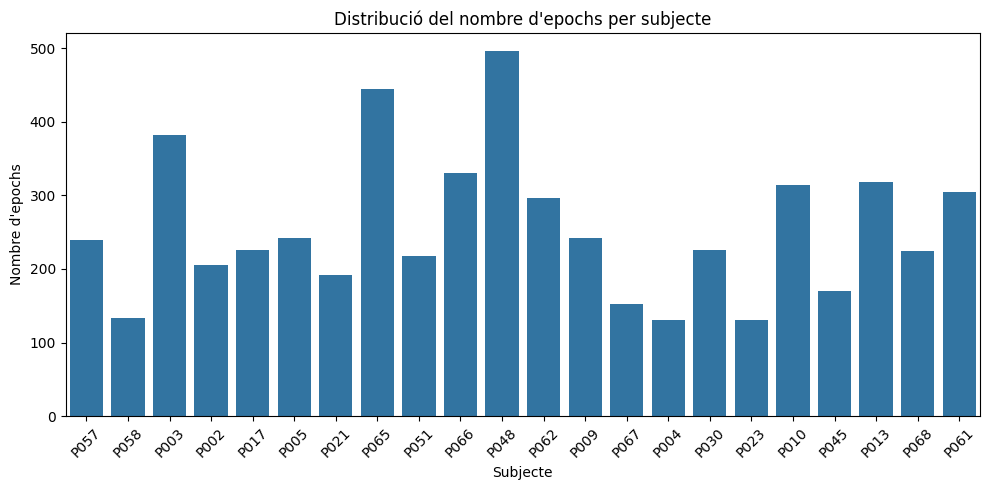

In [ ]:
# Histograma de nombre d'epochs per subjecte
plt.figure(figsize=(10, 5))
sns.countplot(x=subj_list)
plt.xticks(rotation=45)
plt.xlabel("Subjecte")
plt.ylabel("Nombre d'epochs")
plt.title("Distribució del nombre d'epochs per subjecte")
plt.tight_layout()
plt.show()

## 2. Funcions de CV i surrogate

### Decisions de disseny

**Per quin nivell es calcula el surrogate?**  
El surrogate s'avalua **a la mateixa finestra temporal** que l'accuracy real.  
D'aquesta manera, ΔAcc(t) = Acc_real(t) − Acc_chance(t) és una comparació neta:
ambdues xifres es basen en les mateixes mostres temporals i el mateix classificador.

**Paired t-test de grup:**  
Per a cada cel·la (canal, t) comparem el vector d'Acc_real dels subjectes vs el vector
d'Acc_chance. Amb N≥6 subjectes vàlids, el test t aparellat és adequat.  
Criteri robust final: p < 0.05 **i** ΔAcc_grupal > 0 **i** hit-rate ≥ 0.5.


In [ ]:
# Local helpers (choose_n_splits, make_clf, cv_accuracy, surrogate_distribution, balanced_sample)
# have been removed. The logic is now imported from br_analysis.experiments.

## 3. Worker per subjecte (paral·lelitzat)

La funció `_process_subject` encapsula **tot el treball** d'un subjecte:

1. Per a cada finestra temporal, calcula Acc_real i la distribució surrogate **a la mateixa finestra**.
2. Retorna `real_arr[ch, t]`, `chance_mean_arr[ch, t]`, `chance_q95_arr[ch, t]`.

Desacoblar el surrogate per finestra és la **clau de la correctesa**:
usar un surrogate global (finestra completa) com a baseline per finestres individuals
seria inconsistent si la senyalització varia molt al llarg del temps.


In [ ]:
# Local helper _process_subject has been removed.
# The logic is now imported from br_analysis.experiments.

## 4. Quants epochs calen per superar chance? (graella)

Aquí la feature és la sèrie temporal completa (`ANALYSIS_WINDOW`) de cada canal,
i es submostregen n_epochs balancejats per estudiar com evoluciona l'accuracy.

El surrogate es calcula **a la mateixa submostra** per ser consistent.


In [ ]:
# Local helper _epochs_worker has been removed.
# The logic is now imported from br_analysis.experiments.

### 4a Execució (paral·lel per subjectes)

In [ ]:
subject_ids = pd.unique(subj_list).tolist()

CACHE_EPOCHS = CACHE_EPOCHS_DIR / (
    f"epochs_grid_{TASK_TAG}_sub{MAX_SUBJECTS if MAX_SUBJECTS is not None else str(len(subject_ids))}.csv"
)

print(
    f"Graella epochs — {len(subject_ids)} subj × {len(ch_names)} canals × "
    f"{len(EPOCHS_GRID)} punts × {N_REPEATS_EPOCHS} reps …"
)

df_epochs = experiment.run_epochs_grid(X, y, subj_list, ch_names, cache_file=CACHE_EPOCHS)

df_epochs.to_csv(EPOCHS_CSV, index=False)
print(f"Saved table: {EPOCHS_CSV}")
df_epochs.head(10)

Carregant df_epochs des de cache: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i\cache\epochs_grid_c_vs_i_FCz_theta_Oz_alpha_sub22_u1_perm50.csv
Desat taula: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i\tables\epochs_grid_c_vs_i_FCz_theta_Oz_alpha.csv


,subject,electrode,n_epochs_total,acc_real_mean,acc_real_std,acc_chance_mean,acc_chance_q95,delta_acc,delta_acc_q95
0,P002,FCz-theta,20,0.490000,0.106771,0.502833,0.700000,-0.012833,-0.210000
1,P002,FCz-theta,30,0.488889,0.115897,0.506445,0.700000,-0.017556,-0.211111
2,P002,FCz-theta,40,0.531667,0.083400,0.498333,0.650000,0.033333,-0.118333
3,P002,FCz-theta,50,0.506667,0.075425,0.495600,0.640000,0.011067,-0.133333
4,P002,FCz-theta,60,0.517778,0.094959,0.496333,0.617500,0.021444,-0.099722
5,P002,FCz-theta,70,0.510476,0.065666,0.501048,0.614286,0.009429,-0.103810
6,P002,FCz-theta,80,0.508333,0.063355,0.493250,0.600625,0.015083,-0.092292
7,P002,FCz-theta,90,0.500741,0.071947,0.500111,0.588889,0.000630,-0.088148
8,P002,FCz-theta,100,0.516000,0.048415,0.506033,0.600000,0.009967,-0.084000
9,P002,FCz-theta,110,0.505455,0.053916,0.498970,0.581818,0.006485,-0.076364


In [ ]:
# Mostrar df_epochs ordenats per delta_acc_q95 descendent
df_epochs_sorted = df_epochs.sort_values("delta_acc_q95", ascending=False).reset_index(drop=True)
display(df_epochs_sorted.head(10**6))

,subject,electrode,n_epochs_total,acc_real_mean,acc_real_std,acc_chance_mean,acc_chance_q95,delta_acc,delta_acc_q95
0,P057,Oz-alpha,160,0.665833,0.022577,0.500938,0.575000,0.164896,0.090833
1,P057,Oz-alpha,150,0.651556,0.026718,0.497111,0.566667,0.154444,0.084889
2,P057,Oz-alpha,180,0.651481,0.024298,0.498037,0.566667,0.153444,0.084815
3,P057,Oz-alpha,190,0.649825,0.018620,0.501000,0.568684,0.148825,0.081140
4,P057,Oz-alpha,170,0.648235,0.032660,0.500863,0.570882,0.147373,0.077353
...,...,...,...,...,...,...,...,...,...
739,P004,Oz-alpha,30,0.420000,0.134880,0.500444,0.666667,-0.080444,-0.246667
740,P005,FCz-theta,20,0.450000,0.123828,0.507167,0.700000,-0.057167,-0.250000
741,P062,FCz-theta,20,0.446667,0.121747,0.508833,0.700000,-0.062167,-0.253333
742,P045,FCz-theta,20,0.496667,0.116142,0.519167,0.750000,-0.022500,-0.253333


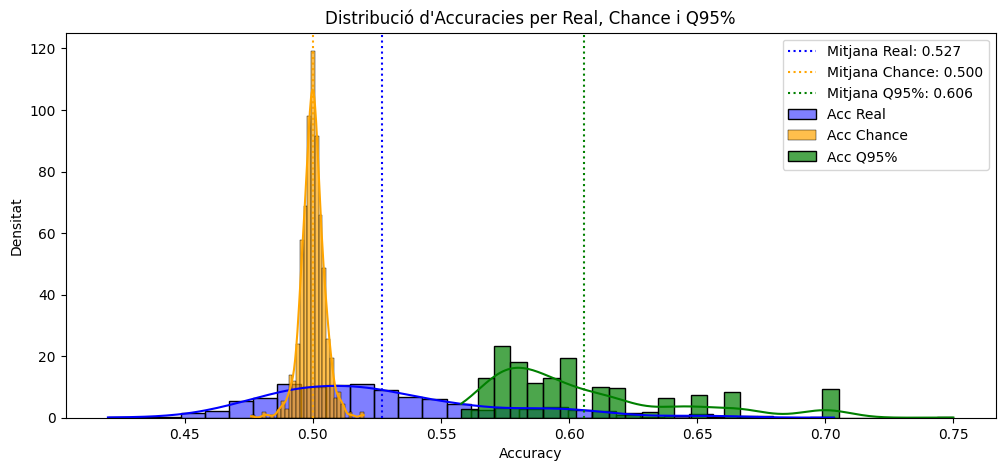

In [ ]:
# Histograma acc_real_mean, acc_chance_mean i acc_chance_q95 amb seaborn
plt.figure(figsize=(12, 5))
sns.histplot(df_epochs, x="acc_real_mean", color="blue", label="Acc Real", kde=True, stat="density", bins=30)
sns.histplot(
    df_epochs, x="acc_chance_mean", color="orange", label="Acc Chance", kde=True, stat="density", bins=30, alpha=0.7
)
sns.histplot(
    df_epochs, x="acc_chance_q95", color="green", label="Acc Q95%", kde=True, stat="density", bins=30, alpha=0.7
)
plt.title("Distribution of Accuracies for Real, Chance and Q95%")
plt.xlabel("Accuracy")
plt.ylabel("Densitat")
# Ensenya mitjanes dels tres grups
mean_real = df_epochs["acc_real_mean"].mean()
mean_chance = df_epochs["acc_chance_mean"].mean()
mean_q95 = df_epochs["acc_chance_q95"].mean()

plt.axvline(mean_real, color="blue", linestyle=":", label=f"Real Mean: {mean_real:.3f}")
plt.axvline(mean_chance, color="orange", linestyle=":", label=f"Mean Chance: {mean_chance:.3f}")
plt.axvline(mean_q95, color="green", linestyle=":", label=f"Q95% Mean: {mean_q95:.3f}")
plt.legend()
plt.savefig(FIGURES_DIR / f"histogram_epochs_{TASK_TAG}.png")
plt.show()

### 4b. Resum numèric epochs → accuracy (sense figures)

Aquesta cel·la deixa només el resum numèric de la graella.
Totes les figures queden centralitzades a l'apartat 7.

In [ ]:
# Resum numèric de la graella d'epochs
grp = (
    df_epochs.groupby("n_epochs_total")
    .agg(
        acc_real_mean=("acc_real_mean", "mean"),
        acc_real_std=("acc_real_std", "mean"),
        acc_chance_mean=("acc_chance_mean", "mean"),
        acc_chance_q95=("acc_chance_q95", "mean"),
    )
    .reset_index()
)

df_surpass = df_epochs[df_epochs["acc_real_mean"] > df_epochs["acc_chance_q95"]]

print("Resum de rendiment (graella epochs):")
print(f"- Files totals: {len(df_epochs)}")
print(f"- Unique subjects: {df_epochs['subject'].nunique()}")
print(f"- Elèctrodes únics: {df_epochs['electrode'].nunique()}")
print(f"- n_epochs provats: {sorted(df_epochs['n_epochs_total'].unique().tolist())}")
print(f"- Global real mean Acc: {df_epochs['acc_real_mean'].mean():.4f}")
print(f"- Global mean chance q95: {df_epochs['acc_chance_q95'].mean():.4f}")

if not df_surpass.empty:
    print(f"- Mínim d'epochs per superar q95: {int(df_surpass['n_epochs_total'].min())}")
    print(
        f"- Combinacions que superen q95: {len(df_surpass)}/{len(df_epochs)} "
        f"({100*len(df_surpass)/len(df_epochs):.1f}%)"
    )
else:
    print("- No combinations exceed the chance q95 in the current grid.")

display(grp.head(10))

Resum de rendiment (graella epochs):
- Files totals: 744
- Subjectes únics: 22
- Elèctrodes únics: 2
- n_epochs provats: [20, 30, 40, 50, 60, 70, 80, 90, 100, 110, 120, 130, 140, 150, 160, 170, 180, 190]
- Acc real mitjana global: 0.5270
- Chance q95 mitjana global: 0.6058
- Mínim d'epochs per superar q95: 20
- Combinacions que superen q95: 80/744 (10.8%)


,n_epochs_total,acc_real_mean,acc_real_std,acc_chance_mean,acc_chance_q95
0,20,0.522197,0.126495,0.500087,0.701136
1,30,0.517222,0.106642,0.501371,0.668258
2,40,0.525606,0.089303,0.501549,0.647301
3,50,0.529212,0.082019,0.499429,0.634136
4,60,0.521490,0.072281,0.498418,0.617576
5,70,0.527035,0.066097,0.499723,0.610828
6,80,0.528144,0.057167,0.499585,0.603281
7,90,0.525707,0.054082,0.500168,0.598813
8,100,0.528712,0.047505,0.499805,0.592784
9,110,0.527645,0.046747,0.499737,0.588926


## 5. Mapa temps×elèctrode (càlcul paral·lel)

### Nota sobre les features per finestra
Cada finestra de `MAP_WINDOW_SEC` és classificada usant **tots els punts temporals
de la finestra** com a features (matriu `trials × win_samples` al LR).
Això és molt més informatiu que usar la mitjana (1 feature), però augmenta el
cost computacional — d'aquí la necessitat del paral·lelisme.


In [ ]:
subject_ids = pd.unique(subj_list).tolist()

# Defineix finestres temporals via TimeWindowGrid
windows = TimeWindowGrid.from_times(times, window_sec=MAP_WINDOW_SEC, step_sec=MAP_STEP_SEC)
starts = windows.starts
stops = windows.stops
window_centers = windows.centers
n_w, n_ch = len(window_centers), len(ch_names)

print(f"Finestres: {n_w} | amplada={MAP_WINDOW_SEC*1000:.0f}ms, pas={MAP_STEP_SEC*1000:.0f}ms")
print(f"Canals: {n_ch} | Subjects: {len(subject_ids)}")
print(
    f"Total de surrogates a calcular: {len(subject_ids)} × {n_ch} × {n_w} × {N_PERM_SURROGATE:,} = "
    f"{len(subject_ids)*n_ch*n_w*N_PERM_SURROGATE:,}"
)

Finestres: 1 | amplada=500ms, pas=100ms
Canals: 2 | Subjectes: 22
Features per finestra: 250 punts × 1 canal
Total de surrogates a calcular: 22 × 2 × 1 × 50 = 2,200


In [ ]:
subject_ids = pd.unique(subj_list).tolist()

print("Executant mapa temps×clúster (paral·lel per subjects) …")
print(f"Subjects: {len(subject_ids)}")

map_data = experiment.run_time_map(X, y, subj_list, ch_names, windows, cache_file=CACHE_MAP_FILE)
real_map = map_data["real_map"]
surr_mean = map_data["surr_mean"]
surr_q95 = map_data["surr_q95"]

delta_map = real_map - surr_mean  # ΔAcc(s, ch, t)
above_q95_map = real_map > surr_q95  # bool(s, ch, t)

print(f"Tensors shape: real_map={real_map.shape}  (subj, clúster, finestra)")

Executant mapa temps×clúster (paral·lel per subjectes) …
Subjectes: 22
Carregant mapa temps×clúster des de cache: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\c_vs_i\cache\map_c_vs_i_FCz_theta_Oz_alpha_sub22.npz
Tensors shape: real_map=(22, 2, 1)  (subj, clúster, finestra)


## 6. Estadística de grup: paired t-test per cel·la (canal, t)

Per a cada cel·la $(ch, t)$ comparem:
- **real_map[:, ch, t]**: accuracy real de cada subjecte
- **surr_mean[:, ch, t]**: accuracy de chance (surrogate mean) del mateix subjecte

Hipòtesi H₁ (one-tailed): Acc_real > Acc_chance → només p/2 si t > 0.
Criteri final robust: `p < 0.05` **i** `ΔAcc_grupal > 0` **i** `hit-rate ≥ 0.50`.


In [ ]:
n_subj_arr = real_map.shape[0]
p_map = np.full((n_ch, n_w), np.nan, dtype=np.float64)
t_map = np.full((n_ch, n_w), np.nan, dtype=np.float64)

for ch_idx in range(n_ch):
    for wi in range(n_w):
        a = real_map[:, ch_idx, wi]
        b = surr_mean[:, ch_idx, wi]
        valid = ~np.isnan(a) & ~np.isnan(b)
        if valid.sum() < 6:
            continue
        t_stat, p_two = ttest_rel(a[valid], b[valid])
        t_map[ch_idx, wi] = t_stat
        # One-tailed: p/2 si t > 0 (direccional: real > chance)
        p_map[ch_idx, wi] = (p_two / 2) if t_stat > 0 else 1.0

mean_delta_map = np.nanmean(delta_map, axis=0)  # (n_ch, n_w)
hit_rate_map = np.nanmean(above_q95_map.astype(float), axis=0)

sig_map = (p_map < 0.05) & (mean_delta_map > 0)

# Onset per elèctrode: primer instant amb superació significativa
onset_time_per_ch = np.full(n_ch, np.nan, dtype=np.float32)
for ch_idx in range(n_ch):
    sig_idx = np.where(sig_map[ch_idx])[0]
    if len(sig_idx) > 0:
        onset_time_per_ch[ch_idx] = float(window_centers[sig_idx[0]])

# Criteri robust: p<0.05 + ΔAcc>0 + hit-rate≥0.5
robust_map = sig_map & (hit_rate_map >= 0.50)

n_sig = int(np.sum(sig_map))
n_rob = int(np.sum(robust_map))
print(f"Cel·les significatives (p<0.05, ΔAcc>0): {n_sig} / {n_ch*n_w}")
print(f"Cel·les robustes (+hit-rate≥0.5):         {n_rob} / {n_ch*n_w}")

Cel·les significatives (p<0.05, ΔAcc>0): 1 / 2
Cel·les robustes (+hit-rate≥0.5):         0 / 2


## 7. Visualitzacions

Totes les figures del notebook es concentren aquí:
- distribucions globals
- corbes epochs→accuracy
- comparativa FCz-theta vs Oz-alpha
- dinàmica temporal i taxa de superació de q95

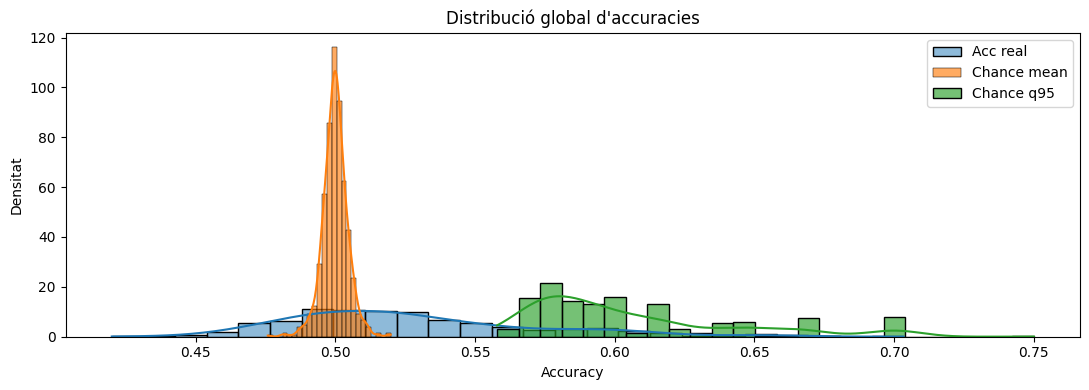

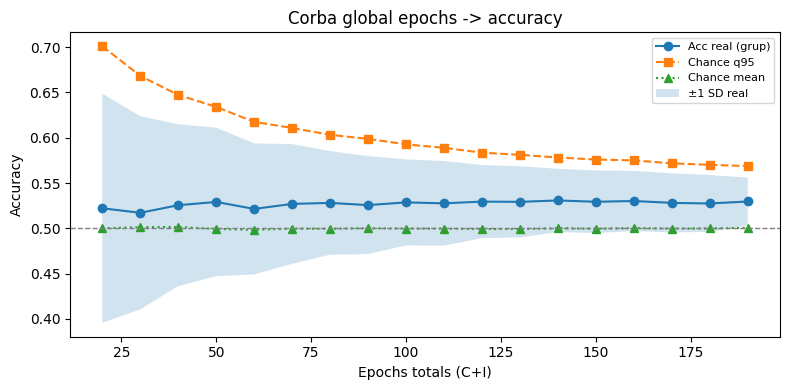

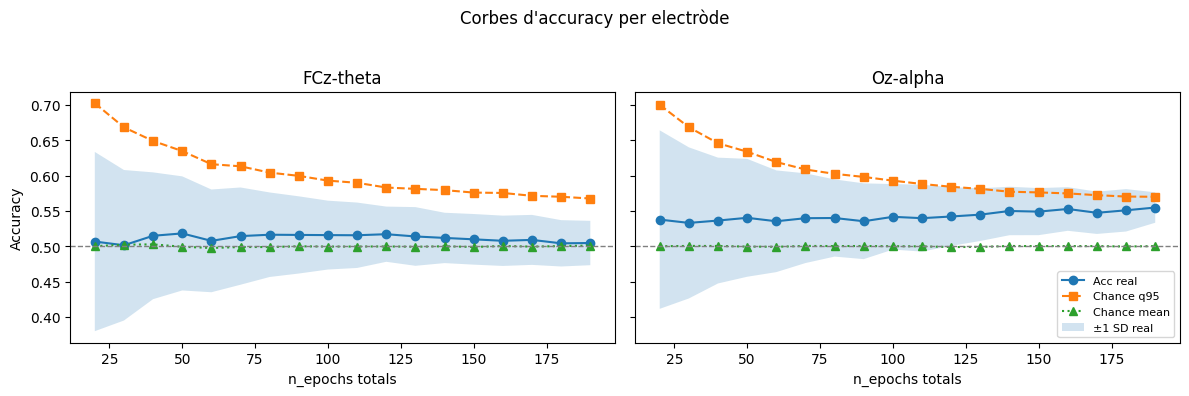

In [ ]:
target_electrodes = ["FCz-theta", "Oz-alpha"]
df_two = df_epochs[df_epochs["electrode"].isin(target_electrodes)].copy()

if df_two.empty:
    raise RuntimeError("No hi ha files de df_epochs per FCz-theta/Oz-alpha.")

# 7a) Distribucions globals (real vs chance)
plt.figure(figsize=(11, 4))
sns.histplot(df_epochs, x="acc_real_mean", color="tab:blue", label="Acc real", kde=True, stat="density", bins=25)
sns.histplot(
    df_epochs,
    x="acc_chance_mean",
    color="tab:orange",
    label="Chance mean",
    kde=True,
    stat="density",
    bins=25,
    alpha=0.65,
)
sns.histplot(
    df_epochs,
    x="acc_chance_q95",
    color="tab:green",
    label="Chance q95",
    kde=True,
    stat="density",
    bins=25,
    alpha=0.65,
)
plt.title("Distribució global d'accuracies")
plt.xlabel("Accuracy")
plt.ylabel("Densitat")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / f"07a_distribucio_accuracies_{TASK_TAG}.png", dpi=150, bbox_inches="tight")
plt.show()

# 7b) Corba epochs -> accuracy (grup)
grp = (
    df_epochs.groupby("n_epochs_total")
    .agg(
        acc_real_mean=("acc_real_mean", "mean"),
        acc_real_std=("acc_real_std", "mean"),
        acc_chance_mean=("acc_chance_mean", "mean"),
        acc_chance_q95=("acc_chance_q95", "mean"),
    )
    .reset_index()
)

plt.figure(figsize=(8, 4))
plt.plot(grp["n_epochs_total"], grp["acc_real_mean"], "o-", label="Acc real (grup)")
plt.plot(grp["n_epochs_total"], grp["acc_chance_q95"], "s--", label="Chance q95")
plt.plot(grp["n_epochs_total"], grp["acc_chance_mean"], "^:", label="Chance mean")
plt.fill_between(
    grp["n_epochs_total"],
    grp["acc_real_mean"] - grp["acc_real_std"],
    grp["acc_real_mean"] + grp["acc_real_std"],
    alpha=0.2,
    label="±1 SD real",
)
plt.axhline(0.5, linestyle="--", color="gray", linewidth=1)
plt.xlabel("Epochs totals (C+I)")
plt.ylabel("Accuracy")
plt.title("Corba global epochs -> accuracy")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / f"07b_corba_global_epochs_accuracy_{TASK_TAG}.png", dpi=150, bbox_inches="tight")
plt.show()

# 7c) Corbes per electròde (només FCz-theta i Oz-alpha)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, elec in zip(axes, target_electrodes):
    d = df_two[df_two["electrode"] == elec]
    g = (
        d.groupby("n_epochs_total")
        .agg(
            acc_real_mean=("acc_real_mean", "mean"),
            acc_real_std=("acc_real_std", "mean"),
            acc_chance_q95=("acc_chance_q95", "mean"),
            acc_chance_mean=("acc_chance_mean", "mean"),
        )
        .reset_index()
    )

    ax.plot(g["n_epochs_total"], g["acc_real_mean"], "o-", label="Acc real")
    ax.plot(g["n_epochs_total"], g["acc_chance_q95"], "s--", label="Chance q95")
    ax.plot(g["n_epochs_total"], g["acc_chance_mean"], "^:", label="Chance mean")
    ax.fill_between(
        g["n_epochs_total"],
        g["acc_real_mean"] - g["acc_real_std"],
        g["acc_real_mean"] + g["acc_real_std"],
        alpha=0.2,
        label="±1 SD real",
    )
    ax.axhline(0.5, linestyle="--", color="gray", linewidth=1)
    ax.set_title(elec)
    ax.set_xlabel("n_epochs totals")

axes[0].set_ylabel("Accuracy")
axes[1].legend(fontsize=8, loc="lower right")
plt.suptitle("Corbes d'accuracy per electròde", fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.95])
fig.savefig(FIGURES_DIR / f"07c_corbes_accuracy_per_electrode_{TASK_TAG}.png", dpi=150, bbox_inches="tight")
plt.show()

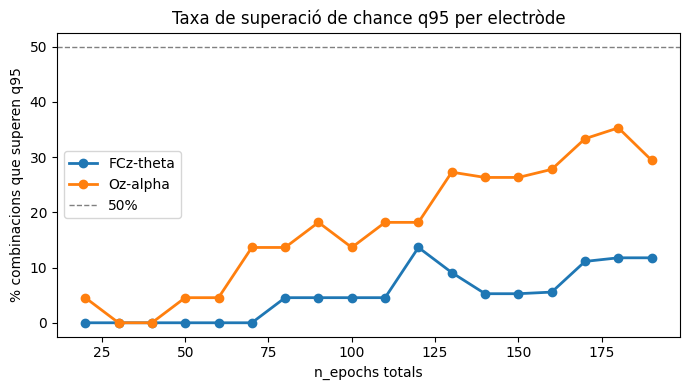

Dinàmica temporal no informativa: només hi ha 1 finestra temporal. Per veure corbes, redueix MAP_WINDOW_SEC i/o MAP_STEP_SEC i recalcula seccions 5 i 6.


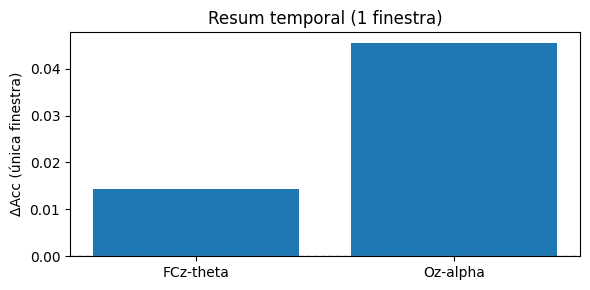


=== RESUM FINAL: FCz-theta vs Oz-alpha ===

FCz-theta:
  - Combinacions que superen q95: 18/372 (4.8%)
  - ΔAcc mitjà: 0.0118
  - Acc màxima: 0.6100

Oz-alpha:
  - Combinacions que superen q95: 62/372 (16.7%)
  - ΔAcc mitjà: 0.0423
  - Acc màxima: 0.7033



In [ ]:
# 7d) Taxa de superació q95 per electròde
df_two["surpass_q95"] = (df_two["acc_real_mean"] > df_two["acc_chance_q95"]).astype(float)
surpass_tbl = (
    df_two.groupby(["electrode", "n_epochs_total"])["surpass_q95"]
    .mean()
    .unstack("electrode")
    .reindex(columns=target_electrodes)
    .sort_index()
)

fig, ax = plt.subplots(figsize=(7, 4))
for elec in target_electrodes:
    ax.plot(
        surpass_tbl.index,
        100 * surpass_tbl[elec].values,
        marker="o",
        linewidth=2,
        label=elec,
    )
ax.axhline(50, color="gray", linestyle="--", linewidth=1, label="50%")
ax.set_xlabel("n_epochs totals")
ax.set_ylabel("% combinacions que superen q95")
ax.set_title("Exceedance rate of chance q95 per electròde")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / f"07d_taxa_superacio_q95_{TASK_TAG}.png", dpi=150, bbox_inches="tight")
plt.show()

# 7e) Dinàmica temporal (si el mapa temps×elèctrode està calculat)
needed = ["window_centers", "mean_delta_map", "hit_rate_map", "ch_names"]
if all(name in globals() for name in needed):
    ch_to_idx = {ch: i for i, ch in enumerate(ch_names)}

    valid_targets = [e for e in target_electrodes if e in ch_to_idx]
    if len(valid_targets) == 0:
        print("No hi ha canals objectiu presents a ch_names per la dinàmica temporal.")
    elif len(window_centers) < 2:
        print(
            "Dinàmica temporal no informativa: només hi ha 1 finestra temporal. "
            "Per veure corbes, redueix MAP_WINDOW_SEC i/o MAP_STEP_SEC i recalcula seccions 5 i 6."
        )
        plt.figure(figsize=(6, 3))
        bars = []
        for elec in valid_targets:
            ci = ch_to_idx[elec]
            bars.append(float(mean_delta_map[ci, 0]))
        plt.bar(valid_targets, bars)
        plt.axhline(0.0, color="gray", linestyle="--", linewidth=1)
        plt.ylabel("ΔAcc (única finestra)")
        plt.title("Resum temporal (1 finestra)")
        plt.tight_layout()
        plt.savefig(FIGURES_DIR / f"07e_dinamica_temporal_resum_1finestra_{TASK_TAG}.png", dpi=150, bbox_inches="tight")
        plt.show()
    else:
        fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
        for elec in valid_targets:
            ci = ch_to_idx[elec]
            axes[0].plot(window_centers, mean_delta_map[ci], linewidth=2, label=elec)
            axes[1].plot(window_centers, hit_rate_map[ci], linewidth=2, label=elec)

        axes[0].axhline(0.0, color="gray", linestyle="--", linewidth=1)
        axes[0].set_ylabel("ΔAcc (real - chance)")
        axes[0].set_title("Dinàmica temporal per electròde")
        axes[0].legend()

        axes[1].axhline(0.5, color="gray", linestyle="--", linewidth=1)
        axes[1].set_ylabel("Hit-rate")
        axes[1].set_xlabel("Temps (s)")
        axes[1].legend()

        fig.tight_layout()
        fig.savefig(FIGURES_DIR / f"07e_dinamica_temporal_per_electrode_{TASK_TAG}.png", dpi=150, bbox_inches="tight")
        plt.show()
else:
    print("Per mostrar la dinàmica temporal, executa primer les seccions 5 i 6.")

print("\n=== RESUM FINAL: FCz-theta vs Oz-alpha ===\n")
for elec in target_electrodes:
    dfe = df_two[df_two["electrode"] == elec]
    surpass = (dfe["acc_real_mean"] > dfe["acc_chance_q95"]).sum()
    total = len(dfe)
    avg_delta = dfe["delta_acc"].mean()
    max_acc = dfe["acc_real_mean"].max()
    print(f"{elec}:")
    print(f"  - Combinacions que superen q95: {surpass}/{total} ({100*surpass/total:.1f}%)")
    print(f"  - ΔAcc mitjà: {avg_delta:.4f}")
    print(f"  - Acc màxima: {max_acc:.4f}")
    print()

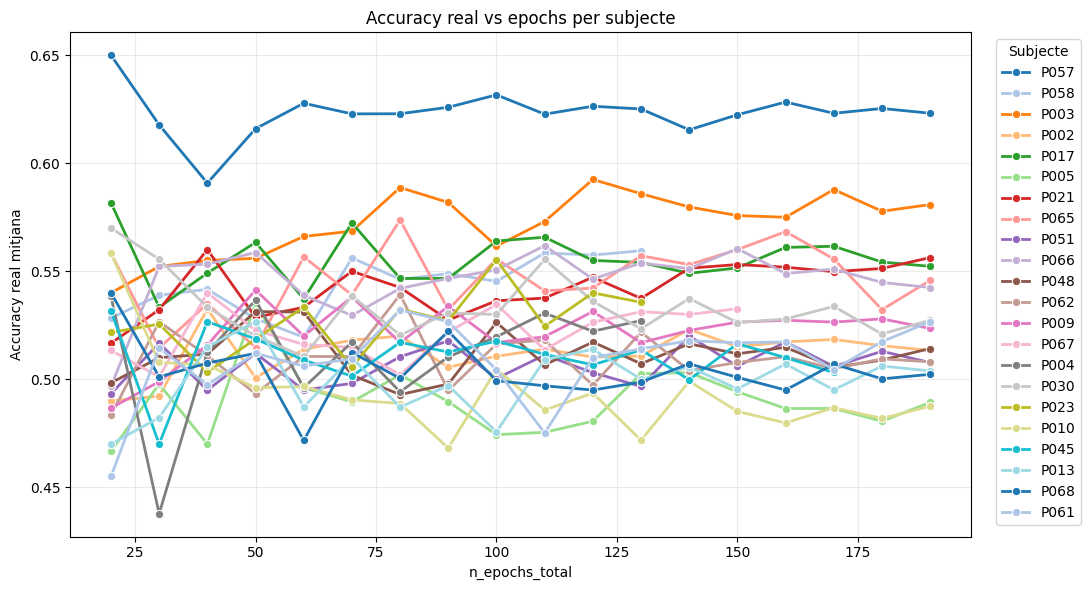

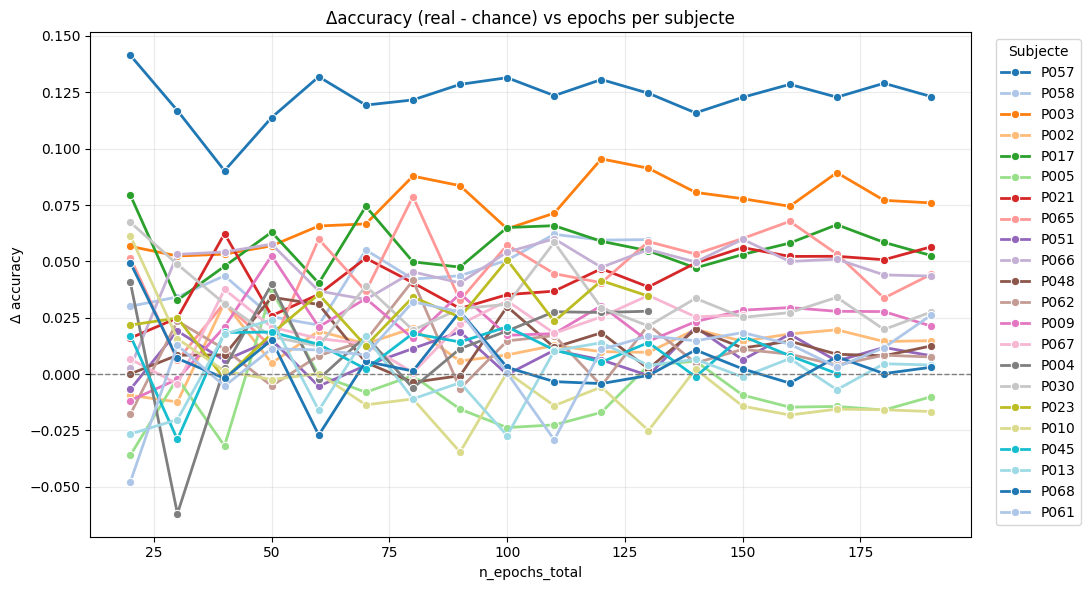

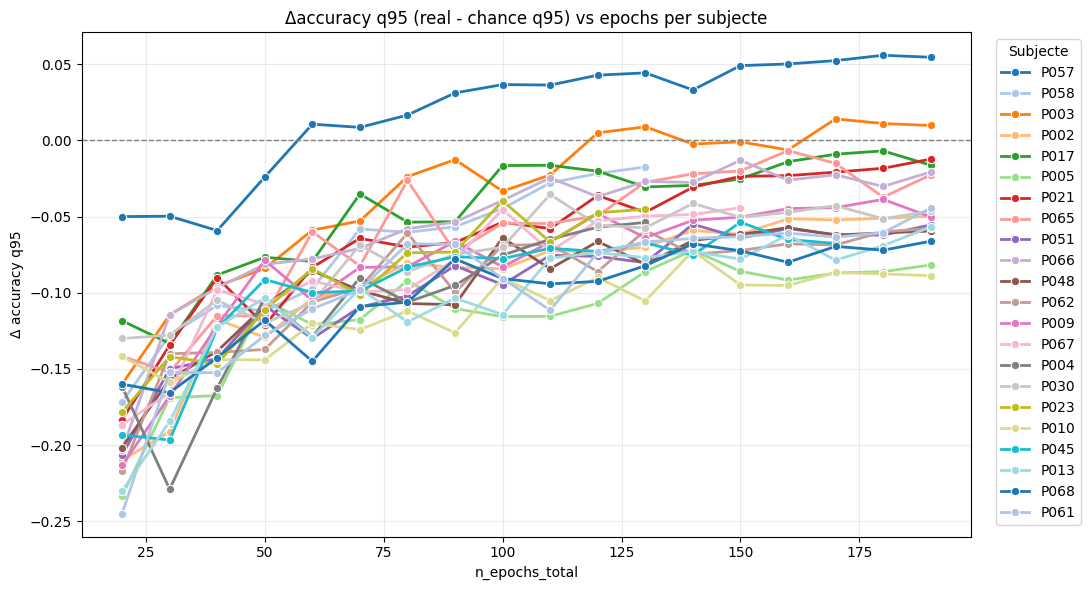

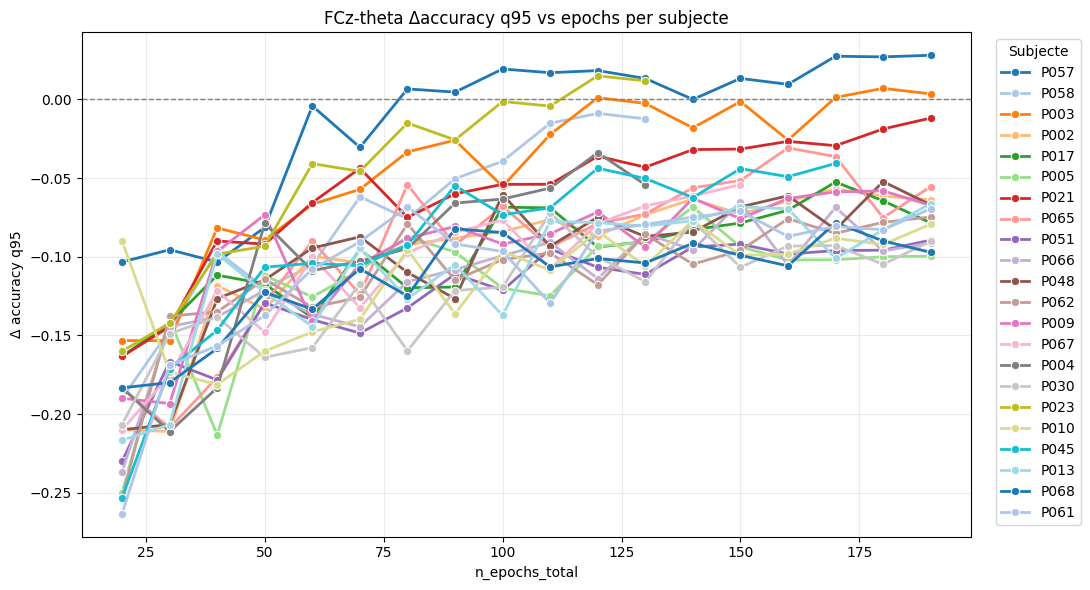

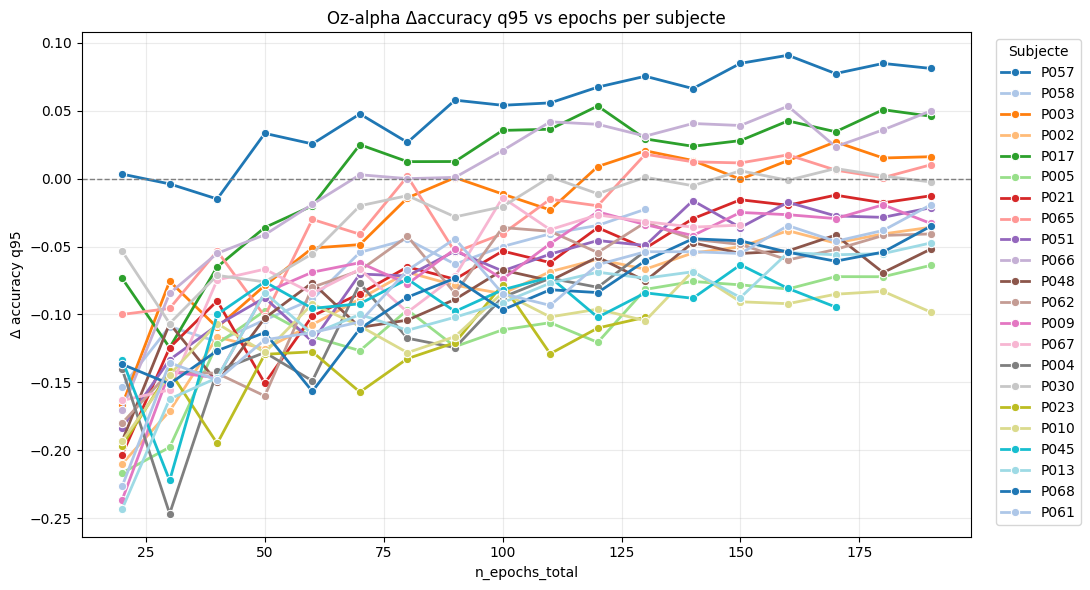

In [ ]:
# Visualitzacions per subjecte (versió simplificada)
subject_order = [s for s in pd.unique(subj_list) if s in df_epochs["subject"].unique()]


def agg_by_subject(metric):
    return (
        df_epochs.groupby(["subject", "n_epochs_total"], as_index=False)[metric]
        .mean()
        .sort_values(["subject", "n_epochs_total"])
    )


def plot_subject_lines(df_plot, y_col, title, y_label, ylim=None):
    plt.figure(figsize=(11, 6))
    sns.lineplot(
        data=df_plot,
        x="n_epochs_total",
        y=y_col,
        hue="subject",
        hue_order=subject_order,
        palette="tab20",
        marker="o",
        linewidth=2,
    )
    if y_col in ["delta_acc", "delta_acc_q95"]:
        plt.axhline(0, color="gray", linestyle="--", linewidth=1)
    plt.title(title)
    plt.xlabel("n_epochs_total")
    plt.ylabel(y_label)
    if ylim is not None:
        plt.ylim(*ylim)
    plt.grid(alpha=0.25)
    plt.legend(title="Subject", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"{y_col}_per_subject_{TASK_TAG}.png", dpi=150, bbox_inches="tight")
    plt.show()


# 1) Accuracy real
plot_subject_lines(
    agg_by_subject("acc_real_mean"),
    y_col="acc_real_mean",
    title="Real accuracy vs epochs by subject",
    y_label="Real mean accuracy",
)

# 2) Delta accuracy
plot_subject_lines(
    agg_by_subject("delta_acc"),
    y_col="delta_acc",
    title="Δaccuracy (real - chance) vs epochs per subjecte",
    y_label="Δ accuracy",
)

# 3) Delta accuracy q95
plot_subject_lines(
    agg_by_subject("delta_acc_q95"),
    y_col="delta_acc_q95",
    title="Δaccuracy q95 (real - chance q95) vs epochs per subjecte",
    y_label="Δ accuracy q95",
)

# 4) Delta accuracy q95 separat per electròde (figures independents)
preferred_electrodes = ["FCz-theta", "Oz-alpha"]
plot_electrodes = [e for e in preferred_electrodes if e in df_epochs["electrode"].unique()]
if len(plot_electrodes) == 0:
    plot_electrodes = df_epochs["electrode"].dropna().unique().tolist()[:2]

df_subj_delta_q95_elec = (
    df_epochs[df_epochs["electrode"].isin(plot_electrodes)]
    .groupby(["subject", "electrode", "n_epochs_total"], as_index=False)["delta_acc_q95"]
    .mean()
    .sort_values(["electrode", "subject", "n_epochs_total"])
)

for elec in plot_electrodes:
    d = df_subj_delta_q95_elec[df_subj_delta_q95_elec["electrode"] == elec]
    plot_subject_lines(
        d,
        y_col="delta_acc_q95",
        title=f"{elec} Δ accuracy q95 vs epochs by subject",
        y_label="Δ accuracy q95",
    )

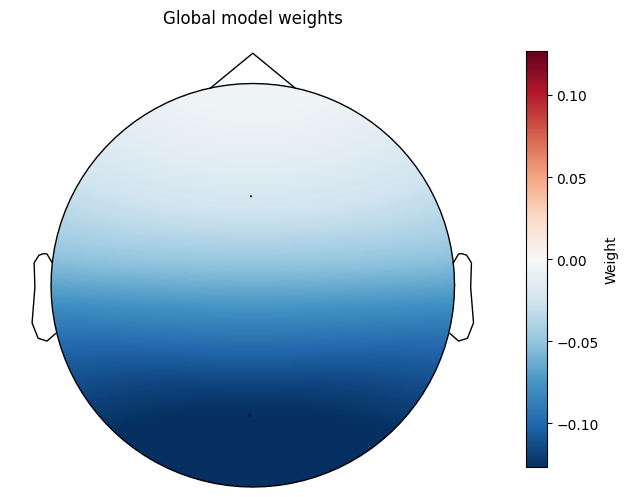

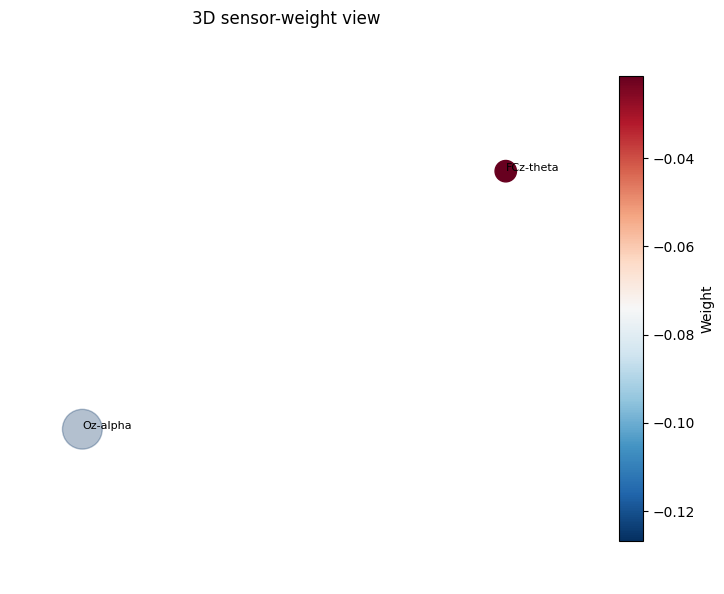

C:\Users\nils\AppData\Local\Temp\ipykernel_28252\35583901.py:111: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=weights[order], y=[display_names[i] for i in order], palette="vlag", orient="h", ax=ax)


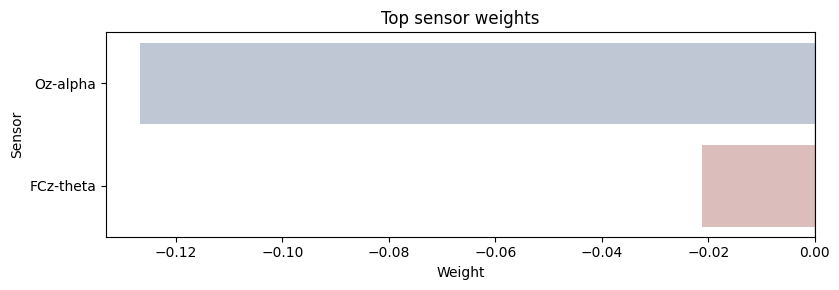

In [ ]:
# 7g) Global model weights and spatial interpretation


def _resolve_topomap_names(n_sensors):
    if "TARGET_BAND_CHANNELS" in globals() and len(TARGET_BAND_CHANNELS) == n_sensors:
        return [ch_name for ch_name, _ in TARGET_BAND_CHANNELS], [
            f"{ch_name}-{band}" for ch_name, band in TARGET_BAND_CHANNELS
        ]
    if "ch_names" in globals() and isinstance(ch_names, (list, tuple, np.ndarray)) and len(ch_names) == n_sensors:
        names = list(ch_names)
        return names, names
    if (
        "target_electrodes" in globals()
        and isinstance(target_electrodes, (list, tuple, np.ndarray))
        and len(target_electrodes) == n_sensors
    ):
        names = list(target_electrodes)
        return names, names
    if "ch_names_dict" in globals() and isinstance(ch_names_dict, dict):
        for value in ch_names_dict.values():
            if isinstance(value, (list, tuple, np.ndarray)) and len(value) == n_sensors:
                names = list(value)
                return names, names
    fallback = [f"ch{i}" for i in range(n_sensors)]
    return fallback, fallback


def _weights_from_classifier(model, n_sensors):
    final_estimator = model.steps[-1][1] if hasattr(model, "steps") else model
    coef = np.asarray(getattr(final_estimator, "coef_", np.array([]))).ravel()
    if coef.size == 0:
        return np.zeros(n_sensors, dtype=float)
    if coef.size == n_sensors:
        return coef.astype(float)
    tri_size = n_sensors * (n_sensors + 1) // 2
    if coef.size == tri_size:
        weights = np.zeros(n_sensors, dtype=float)
        k = 0
        for i in range(n_sensors):
            for j in range(i, n_sensors):
                value = float(abs(coef[k]))
                if i == j:
                    weights[i] += value
                else:
                    weights[i] += 0.5 * value
                    weights[j] += 0.5 * value
                k += 1
        return weights
    return np.abs(np.resize(coef, n_sensors)).astype(float)


if "X" not in globals() or "y" not in globals():
    print("Missing X/y for the interpretation plot.")
else:
    X_feat = np.mean(np.abs(hilbert(np.asarray(X), axis=-1)), axis=-1)
    if X_feat.ndim == 1:
        X_feat = X_feat[:, None]

    model = make_clf()
    model.fit(X_feat, y)

    sensor_names, display_names = _resolve_topomap_names(X_feat.shape[1])
    if len(sensor_names) != X_feat.shape[1]:
        sensor_names = [f"ch{i}" for i in range(X_feat.shape[1])]
        display_names = sensor_names

    weights = _weights_from_classifier(model, len(sensor_names))
    weights = np.nan_to_num(weights.astype(float), nan=0.0)

    info = mne.create_info(sensor_names, sfreq=1.0, ch_types="eeg")
    try:
        info.set_montage("standard_1020", on_missing="ignore")
    except Exception:
        pass

    topomap_title = "Global model weights"
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    try:
        im, _ = mne.viz.plot_topomap(weights, info, axes=ax, show=False, cmap="RdBu_r", contours=0)
        fig.colorbar(im, ax=ax, shrink=0.8, label="Weight")
        ax.set_title(topomap_title)
    except Exception:
        order = np.argsort(np.abs(weights))[::-1]
        ax.bar(
            np.arange(len(order)), weights[order], color=["tab:red" if weights[i] >= 0 else "tab:blue" for i in order]
        )
        ax.set_xticks(np.arange(len(order)))
        ax.set_xticklabels([display_names[i] for i in order], rotation=45, ha="right")
        ax.set_ylabel("Weight")
        ax.set_title(topomap_title)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"07g_model_weights_{TASK_TAG}.png", dpi=160, bbox_inches="tight")
    plt.show()

    fig = plt.figure(figsize=(7.5, 6.5))
    ax3d = fig.add_subplot(111, projection="3d")
    coords = np.array([ch["loc"][:3] for ch in info["chs"]], dtype=float)
    finite = np.isfinite(coords).all(axis=1) & (np.linalg.norm(coords, axis=1) > 0)
    if not np.any(finite):
        theta = np.linspace(0, 2 * np.pi, len(sensor_names), endpoint=False)
        coords = np.column_stack([np.cos(theta), np.sin(theta), np.zeros_like(theta)])
        finite = np.ones(len(sensor_names), dtype=bool)
    coords = coords[finite]
    weights_3d = weights[finite]
    finite_display_names = np.asarray(display_names)[finite]
    sizes = 120 + 700 * (np.abs(weights_3d) / (np.max(np.abs(weights_3d)) + 1e-12))
    sc = ax3d.scatter(coords[:, 0], coords[:, 1], coords[:, 2], c=weights_3d, s=sizes, cmap="RdBu_r", depthshade=True)
    for idx in np.argsort(np.abs(weights_3d))[::-1][: min(5, len(weights_3d))]:
        ax3d.text(coords[idx, 0], coords[idx, 1], coords[idx, 2], finite_display_names[idx], fontsize=8)
    fig.colorbar(sc, ax=ax3d, shrink=0.75, pad=0.08, label="Weight")
    ax3d.set_title("3D sensor-weight view")
    ax3d.set_axis_off()
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"07g_model_weights_3d_{TASK_TAG}.png", dpi=160, bbox_inches="tight")
    plt.show()

    top_n = min(8, len(weights))
    order = np.argsort(np.abs(weights))[::-1][:top_n]
    fig, ax = plt.subplots(figsize=(8.5, max(3.0, 0.45 * top_n + 1.0)))
    sns.barplot(x=weights[order], y=[display_names[i] for i in order], palette="vlag", orient="h", ax=ax)
    ax.axvline(0.0, color="0.5", linewidth=1)
    ax.set_title("Top sensor weights")
    ax.set_xlabel("Weight")
    ax.set_ylabel("Sensor")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"07g_model_weights_bar_{TASK_TAG}.png", dpi=160, bbox_inches="tight")
    plt.show()